# 06 - Trực quan hóa dữ liệu Red Wine Quality

Mục tiêu: bài tập thực hành 1 (mục 1.2.2). Dùng histogram, boxplot, bar chart, violin, scatter plot và heatmap để tìm mẫu, xu hướng và bất thường.

## 1. Load data và kiểm tra nhanh

Loại trùng lặp: 1599 -> 1359 dòng


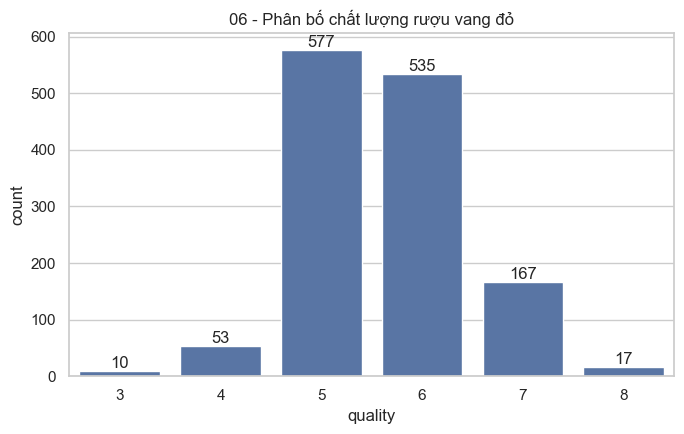

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

wine = doc_csv(can_file('winequality-red.csv', 'winequality_red.csv'))
assert 'quality' in wine.columns, 'Sai file: cần winequality-red.csv của Red Wine Quality'
n0 = len(wine)
wine = wine.drop_duplicates().reset_index(drop=True)
print(f'Loại trùng lặp: {n0} -> {len(wine)} dòng')
features = [c for c in wine.columns if c != 'quality']

plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=wine, x='quality')
ax.bar_label(ax.containers[0])
plt.title('06 - Phân bố chất lượng rượu vang đỏ')
luu_hinh('06_wine_quality_count')

## 2. Phân bố từng biến (đơn biến)

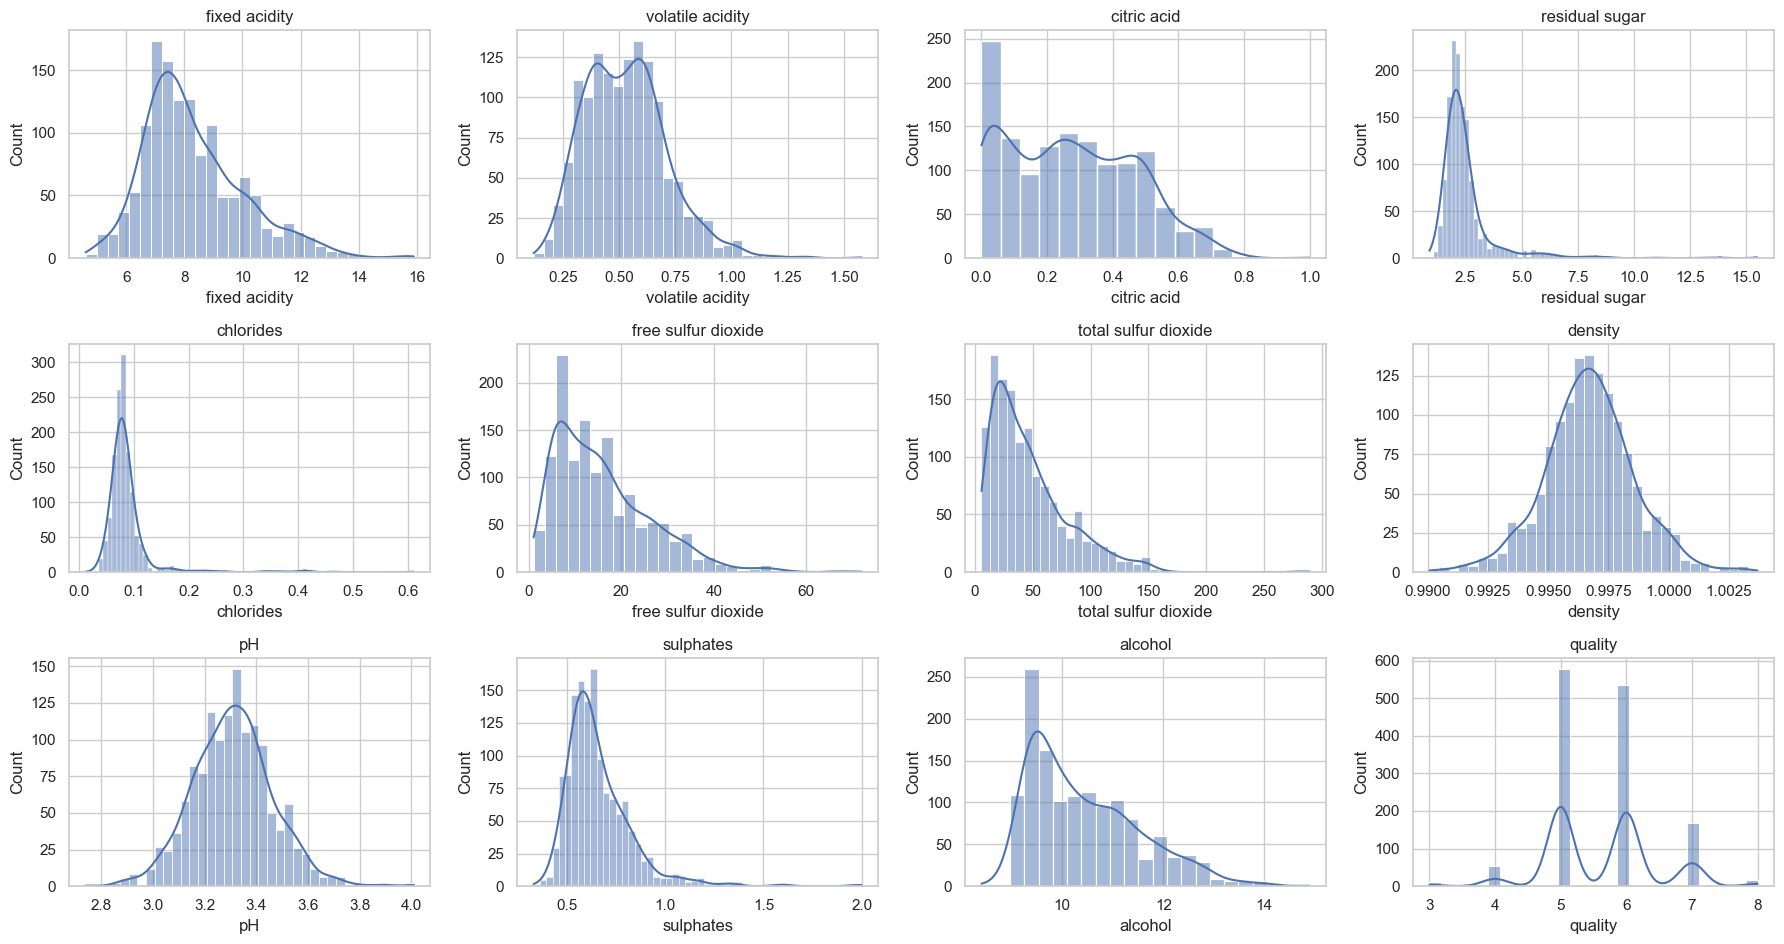

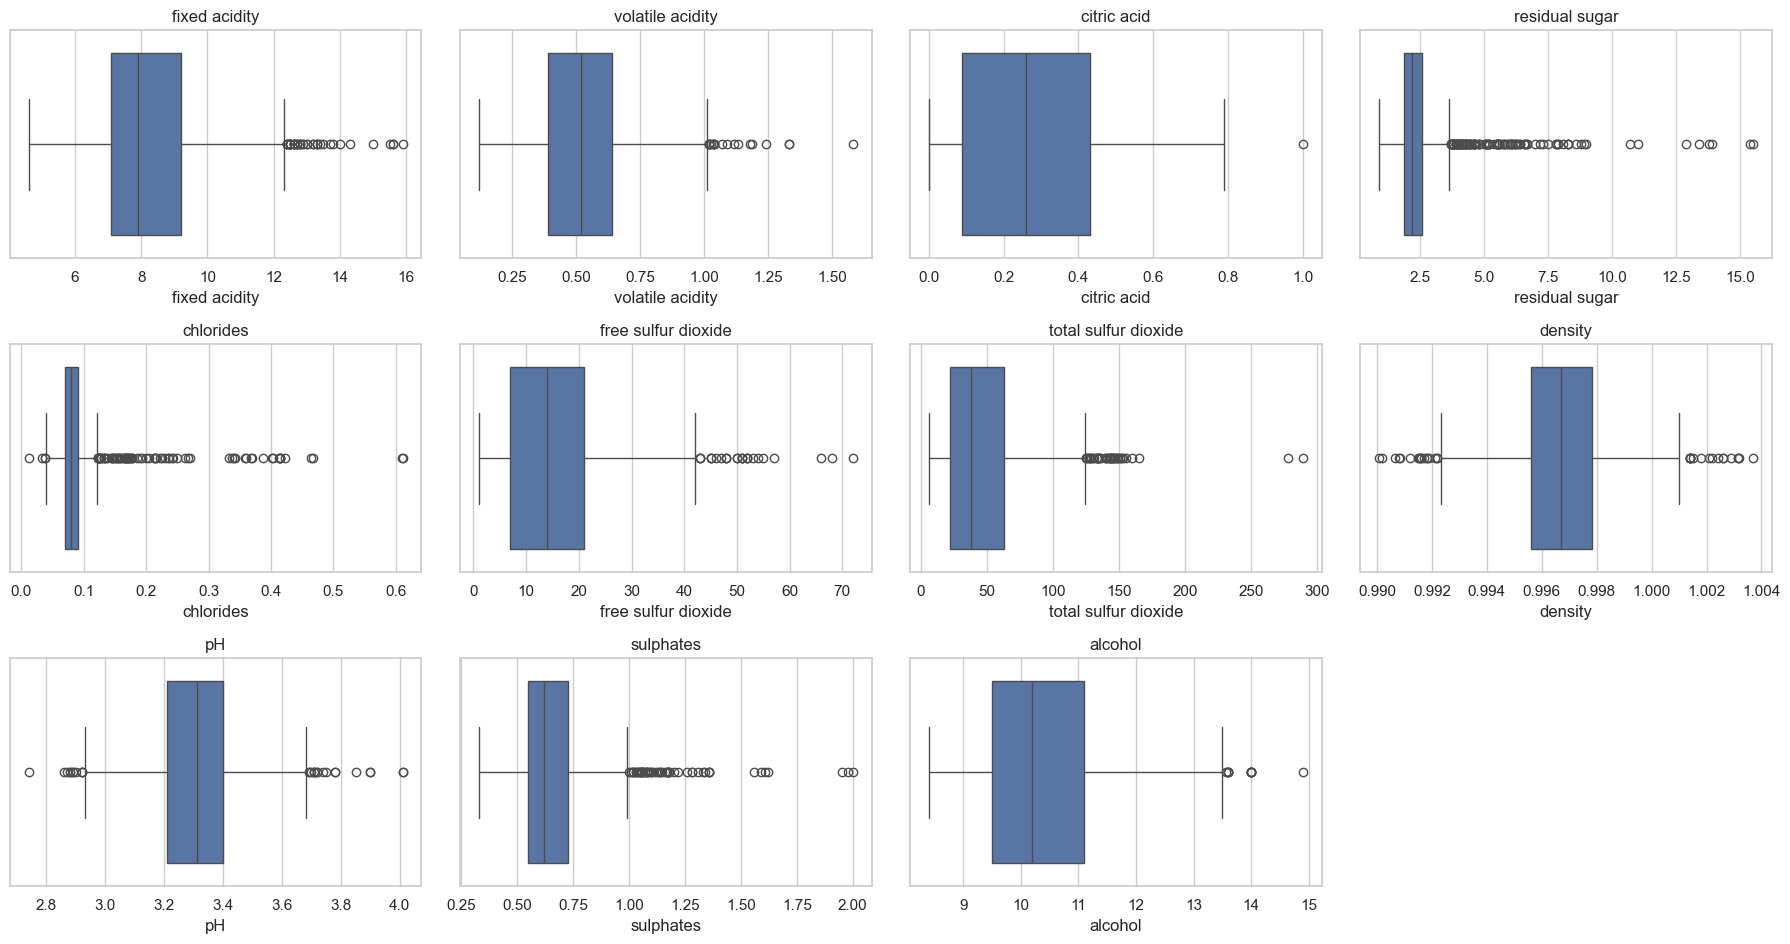

In [2]:
def ve_hist(ax, c):
    sns.histplot(wine[c], kde=True, ax=ax); ax.set_title(c)

def ve_box(ax, c):
    sns.boxplot(x=wine[c], ax=ax); ax.set_title(c)

luoi(wine.columns, ve_hist); luu_hinh('06_wine_histograms')
luoi(features, ve_box); luu_hinh('06_wine_boxplots')

## 3. Biến số theo biến phân loại (`quality`)

Tương quan với quality:
volatile acidity       -0.395
density                -0.184
total sulfur dioxide   -0.178
chlorides              -0.131
pH                     -0.055
free sulfur dioxide    -0.050
residual sugar          0.014
fixed acidity           0.119
citric acid             0.228
sulphates               0.249
alcohol                 0.480
Name: quality, dtype: float64


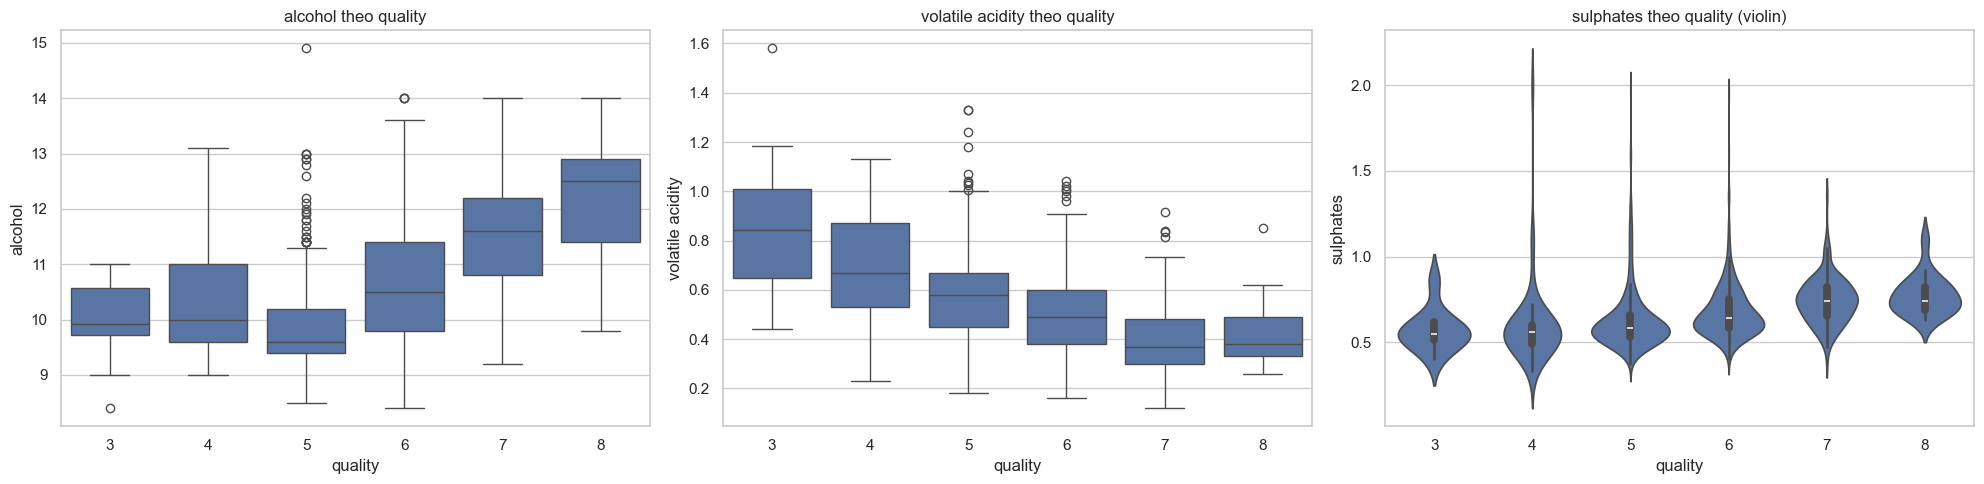

In [3]:
corr_q = wine.corr()['quality'].drop('quality').sort_values()
print('Tương quan với quality:'); print(corr_q.round(3))
top_pos, top_neg = corr_q.index[-1], corr_q.index[0]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=wine, x='quality', y=top_pos, ax=axes[0]); axes[0].set_title(f'{top_pos} theo quality')
sns.boxplot(data=wine, x='quality', y=top_neg, ax=axes[1]); axes[1].set_title(f'{top_neg} theo quality')
sns.violinplot(data=wine, x='quality', y='sulphates', ax=axes[2]); axes[2].set_title('sulphates theo quality (violin)')
luu_hinh('06_wine_by_quality')

## 4. Quan hệ giữa các biến (hai biến)

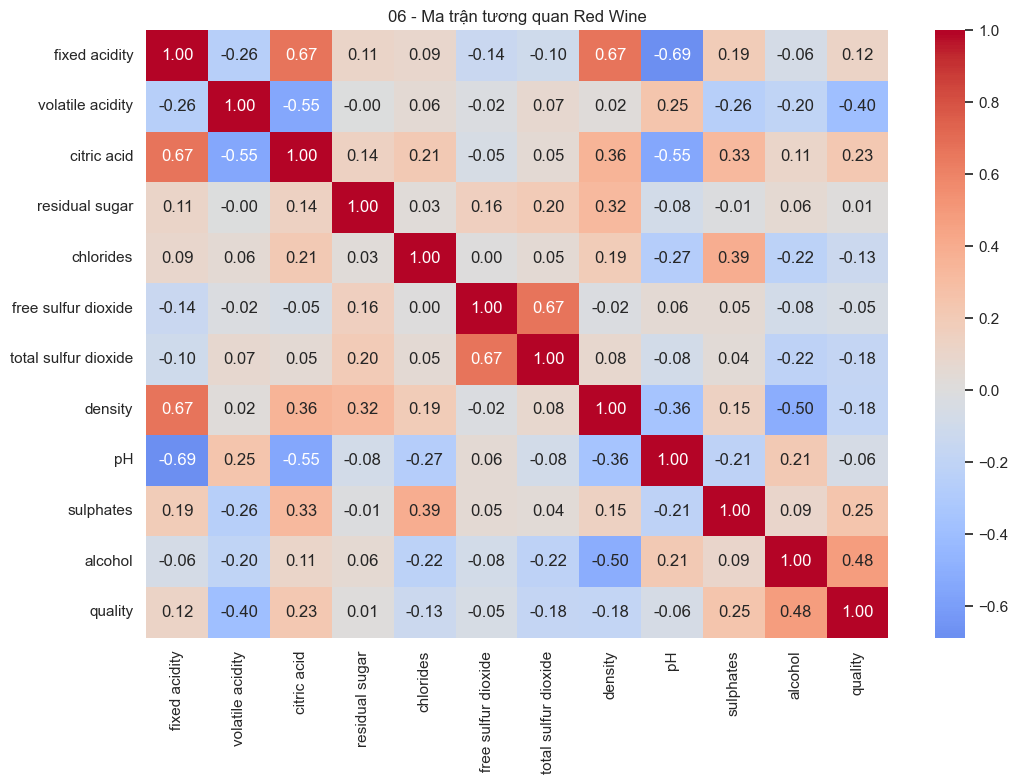

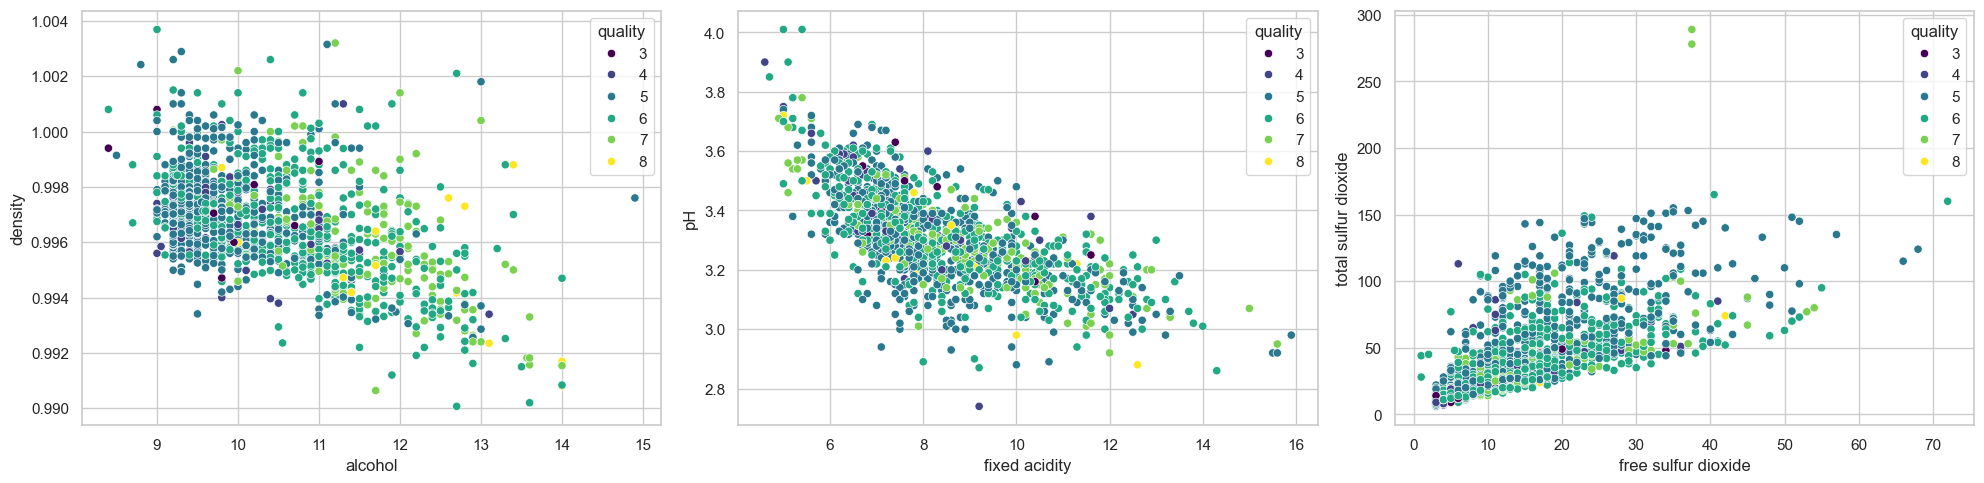

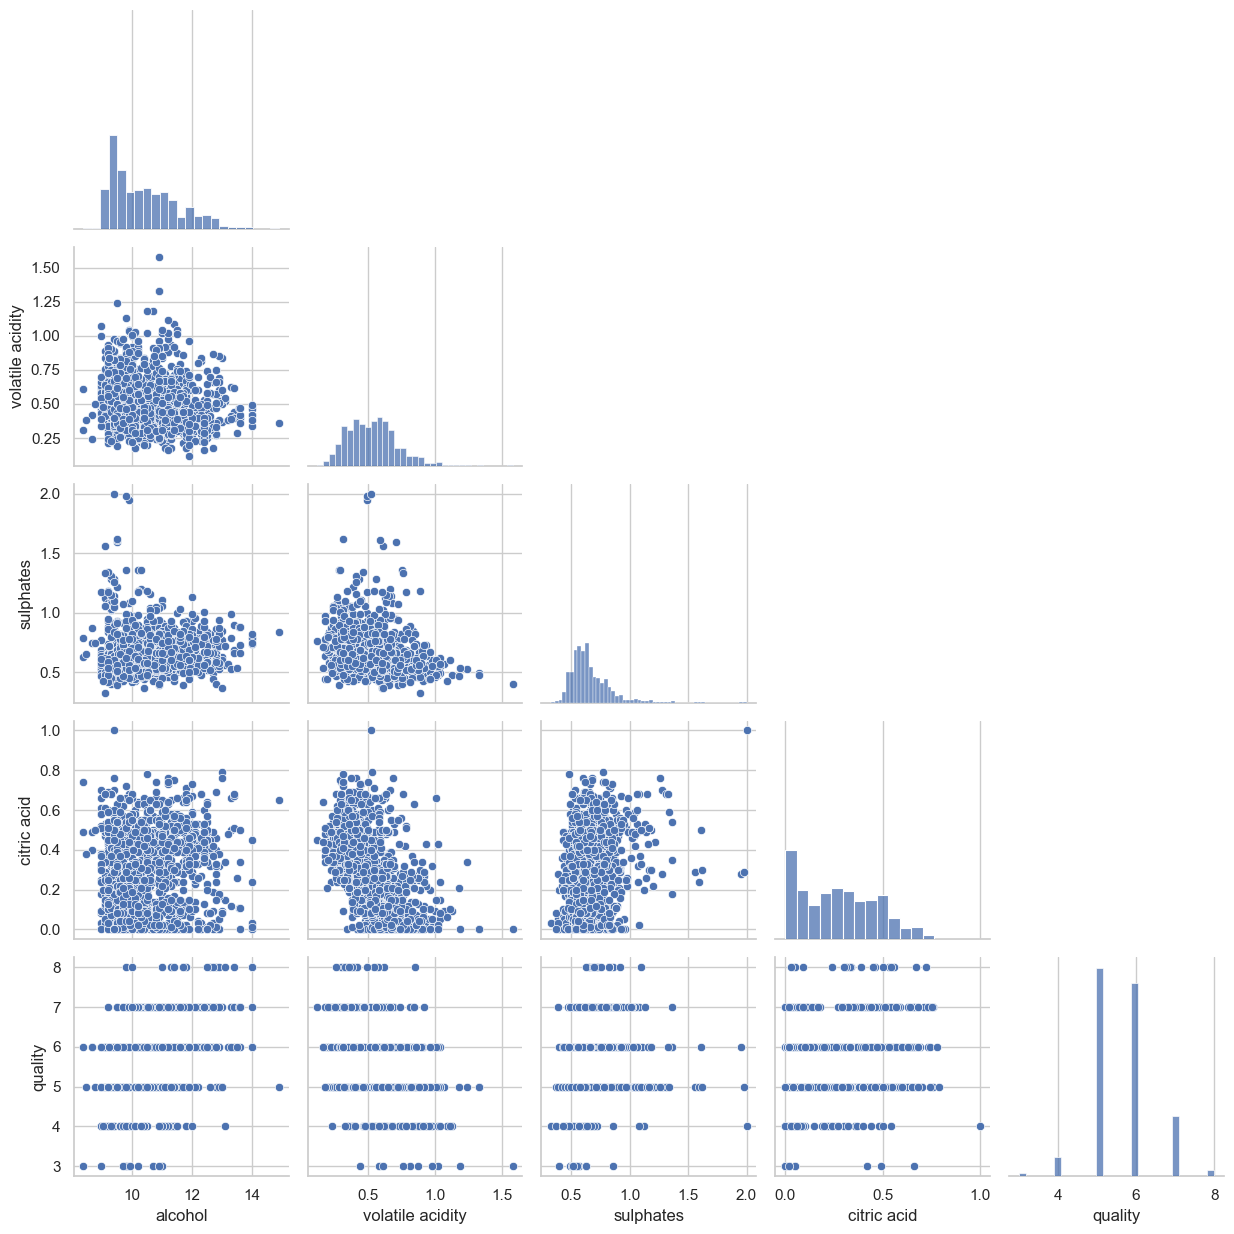

3 cặp đặc trưng tương quan mạnh nhất (|r|):
fixed acidity  pH             0.687
               density        0.670
               citric acid    0.667
dtype: float64
Đã cập nhật: results_summary.csv


In [4]:
plt.figure(figsize=(11, 8))
sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('06 - Ma trận tương quan Red Wine')
luu_hinh('06_wine_corr_heatmap')

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=wine, x='alcohol', y='density', hue='quality', palette='viridis', ax=axes[0])
sns.scatterplot(data=wine, x='fixed acidity', y='pH', hue='quality', palette='viridis', ax=axes[1])
sns.scatterplot(data=wine, x='free sulfur dioxide', y='total sulfur dioxide', hue='quality', palette='viridis', ax=axes[2])
luu_hinh('06_wine_scatter')

top4 = corr_q.abs().nlargest(4).index.tolist()
sns.pairplot(wine[top4 + ['quality']], corner=True)
luu_hinh('06_wine_pairplot_top4')

pairs = wine[features].corr().abs().where(np.triu(np.ones((len(features), len(features)), dtype=bool), k=1)).stack().nlargest(3)
print('3 cặp đặc trưng tương quan mạnh nhất (|r|):'); print(pairs.round(3))
cap_nhat_summary('06_wine_viz', 'winequality-red.csv', wine)

## 5. Nhận xét

Các cặp đặc trưng có |r| cao ở trên cho thấy đa cộng tuyến (ví dụ nhóm acidity và density); khi xây mô hình cần cân nhắc. Biến tương quan mạnh nhất với `quality` hiện rõ qua xu hướng của boxplot theo từng mức chất lượng. Các điểm ngoại lai trong boxplot không bị loại ở bước này, vì mục tiêu của notebook là khám phá.